# Raw data across subcarriers

This notebook reads the **raw I/Q samples** in `raw_traces/` and shows how the signal looks on every subcarrier, for each cluster.

| Step | Plot | What it shows |
|---|---|---|
| 1 | — | settings: which clusters, frames and antenna to look at |
| 2 | — | loading: pilot → 64-point FFT for the measured user's slot and the noise slot |
| 3 | **Raw data as tables** | raw I/Q samples of one frame and its CSI on every subcarrier, as DataFrames |
| 4 | **Full 64-bin spectrum** | all FFT bins, including the 12 empty ones (guard bands and DC), so you can see why they are removed |
| 5 | **52 data subcarriers per cluster** | mean CSI amplitude (dB) per subcarrier, LOS clusters and NLOS clusters |
| 6 | **Per-antenna normalised** | the same after dividing each antenna by its own mean: the frequency *shape* the models see |
| 7 | **Antenna × subcarrier heatmap** | amplitude of every antenna on every subcarrier (one cluster) |
| 8 | **Subcarrier over time (waterfall)** | how each subcarrier changes over frames (one antenna) |
| 9 | **Noise slot per subcarrier** | the noise-only slot: shows the interference spur at subcarrier 13 |
| 10 | **Distribution per subcarrier** | spread of the per-antenna-normalised amplitude per subcarrier, LOS vs NLOS |

Every table is shown as a **pandas DataFrame** and also saved as a CSV file in `results/`.

The processing is the same as in `../preprocess_raw.ipynb` (pilot at sample 47 of each 224-sample slot, FFT, × known LTS, phase calibration). See `../AUDIT.md` for the details.

**Subcarrier numbering.** Plots use the 802.11 index k: −32 … +31 for the 64 FFT bins, and −26 … −1, +1 … +26 for the 52 data subcarriers. Column `i` (0–51) in the model input is k = −26 + i for i < 26, and k = −25 + i for i ≥ 26.

## Step 1: Settings

Loading all frames of all 9 clusters takes a while and needs a lot of memory. By default, `N_FRAMES` frames are taken from each cluster, starting at `START_FRAME` (after the 200 gain-settling frames). That is enough for averages and plots.

In [1]:
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 70)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

def show(df, name, decimals=3):
    # display a table (float32 shown as plain decimals) and save it as results/<name>.csv
    df = df.astype({col: "float64" for col in df.select_dtypes("float32").columns}).round(decimals)
    display(df)
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))

RAW_DIR = "../../tvt_open_source/raw_traces"
OUT_DIR = "results"

LOS_CLUSTERS = ["LOS_cluster1", "LOS_cluster2", "LOS_cluster3", "LOS_cluster4"]
NLOS_CLUSTERS = ["NLOS_cluster1", "NLOS_cluster2", "NLOS_cluster3", "NLOS_cluster4", "NLOS_cluster5"]
ALL_CLUSTERS = LOS_CLUSTERS + NLOS_CLUSTERS

START_FRAME = 200       # skip the gain-settling frames
N_FRAMES = 1000         # frames per cluster (use None for all frames)
HEATMAP_CLUSTER = "LOS_cluster1"     # Step 7
WATERFALL_CLUSTER = "NLOS_cluster1"  # Step 8
WATERFALL_ANTENNA = 0                # Step 8 (0-63)
TABLE_CLUSTER = "LOS_cluster1"       # Step 3: raw-data tables
TABLE_FRAME = 0                      # Step 3: which loaded frame (0 = START_FRAME)
TABLE_ANTENNA = 0                    # Step 3: which antenna (0-63)

# ---- raw-trace layout (see AUDIT.md) ----
SAMPLES_PER_SLOT = 224
LTS_OFFSET = 47
FFT_SIZE = 64
NOISE_SLOT = 4
LTS_FREQ = np.array([0,0,0,0,0,0,1,1,-1,-1,1,1,-1,1,-1,1,1,1,1,1,1,-1,-1,1,1,-1,1,-1,1,1,1,1,
                     0,1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,-1,-1,1,1,-1,-1,1,-1,1,-1,1,1,1,1,0,0,0,0,0], dtype=np.float32)
NULL_BINS = [0, 1, 2, 3, 4, 5, 32, 59, 60, 61, 62, 63]
DATA_BINS = np.array([b for b in range(FFT_SIZE) if b not in NULL_BINS])
ANT_IDX = np.delete(np.arange(4, 72), [32, 33, 34, 35])        # 64 antennas kept

K_ALL = np.arange(FFT_SIZE) - 32        # 802.11 index of each FFT bin (after fftshift)
K_DATA = K_ALL[DATA_BINS]               # -26..-1, 1..26

def slots_for(cluster):
    return (0, 3) if cluster.startswith("LOS") else (3, 0)     # (measured user, calibration node)

# chart colours (reference palette): categorical order, never cycled
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "lines.linewidth": 2,
})
os.makedirs(OUT_DIR, exist_ok=True)

## Step 2: Load the raw data and take the FFT

For every cluster, the selected frames of `Pilot_Samples` are read. For three slots:
- the **measured user's** pilot: the CSI the models use;
- the **calibration node's** pilot: used only to correct the phase;
- the **noise slot**: nobody transmits, so it shows the receiver noise and interference.

For each slot, the 64 pilot samples go through a 64-point FFT (shifted so bin 32 is DC) and are multiplied by the known LTS. The noise slot is not multiplied by the LTS, because it has no pilot.

Stored per cluster:
- `spec64[c]`: mean |FFT|² over frames and antennas, for all 64 bins (shape 64);
- `csi[c]`: calibrated complex CSI on the 52 data subcarriers, shape (frames, 64 antennas, 52);
- `noise64[c]`: mean noise power per bin (shape 64).

In [2]:
def fft_slot(block, slot, use_lts=True):
    s = slot * SAMPLES_PER_SLOT + LTS_OFFSET
    iq = (block[:, :, s:s + FFT_SIZE, 0] + 1j * block[:, :, s:s + FFT_SIZE, 1]).astype(np.complex64) * 2 ** -15
    h = np.fft.fftshift(np.fft.fft(iq, FFT_SIZE, axis=2), axes=2)
    if use_lts:
        h = h * LTS_FREQ
    return h[:, ::-1, :][:, ANT_IDX, :]          # (frames, 64 antennas, 64 bins)

spec64, noise64, csi, summary = {}, {}, {}, []
for c in ALL_CLUSTERS:
    with h5py.File(os.path.join(RAW_DIR, f"channe14_{c}.hdf5"), "r") as f:
        ds = f["Pilot_Samples"]
        stop = ds.shape[0] - 1 if N_FRAMES is None else min(START_FRAME + N_FRAMES, ds.shape[0] - 1)
        block = ds[START_FRAME:stop]
    meas, cal = slots_for(c)
    raw = fft_slot(block, meas, use_lts=False)           # plain FFT (no LTS): shows energy in every bin
    spec64[c] = (np.abs(raw) ** 2).mean(axis=(0, 1))
    h_meas = fft_slot(block, meas)[:, :, DATA_BINS]
    h_cal = fft_slot(block, cal)[:, :, DATA_BINS]
    csi[c] = h_meas / (h_cal / np.abs(h_cal))             # phase calibration (amplitude unchanged)
    noise64[c] = (np.abs(fft_slot(block, NOISE_SLOT, use_lts=False)) ** 2).mean(axis=(0, 1))
    if c == TABLE_CLUSTER:
        raw_block = block[TABLE_FRAME]                  # (72 radio channels, 1120 samples, 2) for Step 3
    summary.append({"cluster": c, "class": "LOS" if c.startswith("LOS") else "NLOS",
                    "first frame": START_FRAME, "last frame": stop - 1, "frames loaded": len(block),
                    "CSI shape": str(csi[c].shape),
                    "mean |H| (dB)": 20 * np.log10(np.abs(csi[c]).mean())})
    del block, raw, h_meas, h_cal

df = pd.DataFrame(summary).set_index("cluster")
show(df, "loaded_clusters", 2)

,class,first frame,last frame,frames loaded,CSI shape,mean |H| (dB)
cluster,,,,,,
LOS_cluster1,LOS,200,1199,1000,"(1000, 64, 52)",5.03
LOS_cluster2,LOS,200,1199,1000,"(1000, 64, 52)",4.82
LOS_cluster3,LOS,200,1199,1000,"(1000, 64, 52)",3.29
LOS_cluster4,LOS,200,1199,1000,"(1000, 64, 52)",4.32
NLOS_cluster1,NLOS,200,1199,1000,"(1000, 64, 52)",3.58
NLOS_cluster2,NLOS,200,1199,1000,"(1000, 64, 52)",-0.06
NLOS_cluster3,NLOS,200,1199,1000,"(1000, 64, 52)",3.94
NLOS_cluster4,NLOS,200,1199,1000,"(1000, 64, 52)",3.06
NLOS_cluster5,NLOS,200,1199,1000,"(1000, 64, 52)",4.07


## Step 3: Raw data as tables

Three tables for one frame (`TABLE_FRAME`), one antenna (`TABLE_ANTENNA`) of `TABLE_CLUSTER`:

1. **Raw I/Q samples:** the 64 pilot samples of the measured user's slot, exactly as stored in the file (int16), and their amplitude.
2. **All 64 FFT bins** of those samples: 802.11 index k, whether the bin is kept, and its amplitude.
3. **CSI on the 52 data subcarriers** after × LTS and phase calibration: real and imaginary part, amplitude, amplitude in dB and phase. This is one row of the model input before normalisation.

In [3]:
meas, cal = slots_for(TABLE_CLUSTER)
ant_channel = ANT_IDX[TABLE_ANTENNA]                       # position in the reversed antenna order
radio = raw_block.shape[0] - 1 - ant_channel               # radio channel (0-71) in the file
s0 = meas * SAMPLES_PER_SLOT + LTS_OFFSET
I = raw_block[radio, s0:s0 + FFT_SIZE, 0].astype(int)
Q = raw_block[radio, s0:s0 + FFT_SIZE, 1].astype(int)

df = pd.DataFrame({"sample in file": np.arange(s0, s0 + FFT_SIZE), "I (int16)": I, "Q (int16)": Q,
                   "|I + jQ| (scaled)": np.abs((I + 1j * Q) * 2 ** -15)})
df.index.name = "pilot sample"
print(f"1) raw pilot samples: {TABLE_CLUSTER}, frame {START_FRAME + TABLE_FRAME}, antenna {TABLE_ANTENNA} "
      f"(radio channel {radio}), slot {meas}")
show(df, "raw_pilot_samples", 5)

x = (I + 1j * Q).astype(np.complex64) * 2 ** -15
X = np.fft.fftshift(np.fft.fft(x, FFT_SIZE))
df = pd.DataFrame({"802.11 k": K_ALL, "kept": [b in DATA_BINS for b in range(FFT_SIZE)],
                   "|FFT|": np.abs(X), "|FFT| (dB)": 20 * np.log10(np.abs(X) + 1e-12)})
df.index.name = "FFT bin"
print("2) all 64 FFT bins of these samples")
show(df, "raw_fft_64_bins", 4)

h = csi[TABLE_CLUSTER][TABLE_FRAME, TABLE_ANTENNA]          # (52,) complex
df = pd.DataFrame({"802.11 k": K_DATA, "Re(H)": h.real, "Im(H)": h.imag, "|H|": np.abs(h),
                   "|H| (dB)": 20 * np.log10(np.abs(h)), "phase (rad)": np.angle(h),
                   "|H| / antenna mean": np.abs(h) / np.abs(h).mean()})
df.index.name = "model column"
print("3) calibrated CSI on the 52 data subcarriers")
show(df, "csi_52_subcarriers", 4)

1) raw pilot samples: LOS_cluster1, frame 200, antenna 0 (radio channel 67), slot 0


,sample in file,I (int16),Q (int16),|I + jQ| (scaled)
pilot sample,,,,
0,47,-5875,-8406,0.31297
1,48,-9765,8328,0.39166
2,49,7906,8593,0.35634
3,50,2390,10281,0.32212
4,51,-11750,-2234,0.36501
5,52,-1937,-859,0.06466
6,53,2171,9000,0.28254
7,54,12609,-2671,0.39333
8,55,8812,6171,0.32831


2) all 64 FFT bins of these samples


,802.11 k,kept,|FFT|,|FFT| (dB)
FFT bin,,,,
0,-32,False,0.1313,-17.6323
1,-31,False,0.0697,-23.1411
2,-30,False,0.0900,-20.9147
3,-29,False,0.0977,-20.2024
4,-28,False,0.2237,-13.0051
5,-27,False,0.0929,-20.6362
6,-26,True,2.3751,7.5136
7,-25,True,2.3075,7.2629
8,-24,True,2.4711,7.8580


3) calibrated CSI on the 52 data subcarriers


,802.11 k,Re(H),Im(H),|H|,|H| (dB),phase (rad),|H| / antenna mean
model column,,,,,,,
0,-26,1.4834,1.8549,2.3751,7.5136,0.8962,0.8591
1,-25,1.0425,2.0586,2.3075,7.2629,1.1020,0.8347
2,-24,0.5465,2.4100,2.4711,7.8580,1.3478,0.8939
3,-23,0.0762,2.4419,2.4431,7.7589,1.5396,0.8837
4,-22,-0.4601,2.4797,2.5221,8.0351,1.7542,0.9123
5,-21,-0.9187,2.2326,2.4142,7.6556,1.9612,0.8733
6,-20,-1.5092,2.0085,2.5123,8.0014,2.2152,0.9087
7,-19,-1.8697,1.7270,2.5453,8.1147,2.3958,0.9207
8,-18,-2.1937,1.2484,2.5240,8.0419,2.6242,0.9130


## Step 4: Full 64-bin spectrum

The mean power in each of the 64 FFT bins of the measured user's pilot, relative to the strongest bin. The shaded bins are the **12 empty subcarriers** (6 lower guard, DC, 5 upper guard). The guard bins carry almost no energy; the DC bin carries receiver DC offset, not channel information. Both are removed, leaving the 52 data subcarriers.

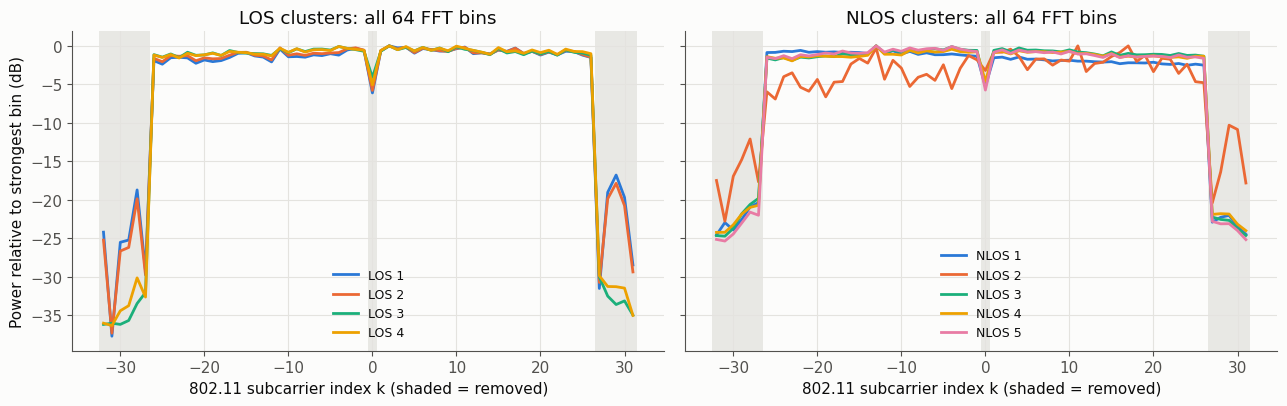

power per FFT bin, relative to the strongest bin (dB)


,802.11 k,kept,LOS 1,LOS 2,LOS 3,LOS 4,NLOS 1,NLOS 2,NLOS 3,NLOS 4,NLOS 5
FFT bin,,,,,,,,,,,
0,-32,False,-24.19,-25.21,-36.16,-36.00,-24.56,-17.47,-24.63,-24.22,-25.13
1,-31,False,-37.69,-37.30,-36.00,-36.32,-22.94,-22.76,-24.71,-24.20,-25.34
2,-30,False,-25.50,-26.64,-36.16,-34.39,-23.90,-16.93,-23.69,-23.23,-24.43
3,-29,False,-25.21,-26.17,-35.65,-33.73,-22.57,-14.77,-21.81,-21.84,-23.01
4,-28,False,-18.70,-19.85,-33.45,-30.12,-20.91,-12.09,-20.59,-20.97,-21.59
5,-27,False,-29.23,-29.76,-32.02,-32.61,-20.36,-17.66,-19.80,-20.69,-21.99
6,-26,True,-1.92,-1.62,-1.14,-1.19,-0.87,-5.97,-1.59,-1.40,-1.49
7,-25,True,-2.38,-2.06,-1.47,-1.51,-0.85,-6.90,-1.82,-1.61,-1.66
8,-24,True,-1.54,-1.26,-1.05,-1.12,-0.70,-4.00,-1.52,-1.58,-1.27


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, group, title in [(axes[0], LOS_CLUSTERS, "LOS clusters"), (axes[1], NLOS_CLUSTERS, "NLOS clusters")]:
    ax.set_axisbelow(True)
    for b in NULL_BINS:
        ax.axvspan(K_ALL[b] - 0.5, K_ALL[b] + 0.5, color=GRID, alpha=0.8, linewidth=0)
    for i, c in enumerate(group):
        p = spec64[c]
        ax.plot(K_ALL, 10 * np.log10(p / p.max()), color=CAT[i], label=c.replace("_cluster", " "))
    ax.set_xlabel("802.11 subcarrier index k (shaded = removed)")
    ax.set_title(f"{title}: all 64 FFT bins")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Power relative to strongest bin (dB)")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "spectrum_64_bins.png"), dpi=150)
plt.show()

df = pd.DataFrame({c.replace("_cluster", " "): 10 * np.log10(spec64[c] / spec64[c].max()) for c in ALL_CLUSTERS})
df.insert(0, "802.11 k", K_ALL)
df.insert(1, "kept", [b in DATA_BINS for b in range(FFT_SIZE)])
df.index.name = "FFT bin"
print("power per FFT bin, relative to the strongest bin (dB)")
show(df, "spectrum_64_bins", 2)

## Step 5: 52 data subcarriers per cluster (absolute amplitude)

The mean CSI amplitude (in dB) of each data subcarrier, averaged over frames and antennas. These are **absolute** levels, so they include the receive-gain difference (35 dB for LOS, 65 dB for NLOS recordings). Compare the **shape** across subcarriers, not the level between the two panels.

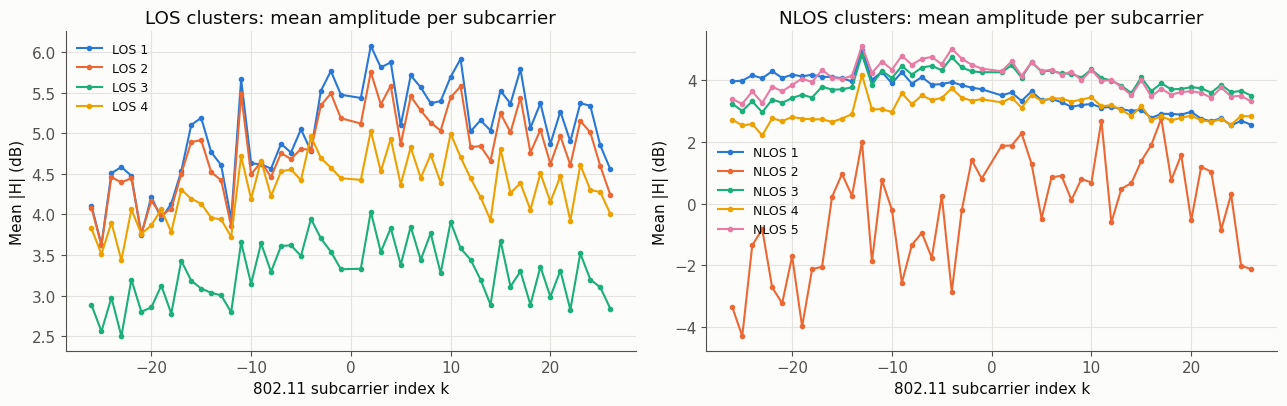

mean |H| per subcarrier (dB), averaged over frames and antennas


,802.11 k,LOS 1,LOS 2,LOS 3,LOS 4,NLOS 1,NLOS 2,NLOS 3,NLOS 4,NLOS 5
model column,,,,,,,,,,
0,-26,4.11,4.08,2.89,3.83,3.96,-3.35,3.24,2.72,3.39
1,-25,3.63,3.62,2.56,3.51,3.99,-4.30,3.01,2.54,3.24
2,-24,4.51,4.46,2.98,3.90,4.16,-1.36,3.32,2.58,3.64
3,-23,4.58,4.39,2.50,3.43,4.07,-0.83,2.96,2.21,3.27
4,-22,4.48,4.45,3.20,4.06,4.30,-2.72,3.38,2.77,3.79
5,-21,3.75,3.76,2.80,3.76,4.08,-3.23,3.27,2.68,3.65
6,-20,4.22,4.17,2.85,3.87,4.18,-1.71,3.43,2.81,3.85
7,-19,3.95,3.99,3.12,4.06,4.13,-3.98,3.53,2.76,4.06
8,-18,4.13,4.07,2.78,3.78,4.18,-2.13,3.44,2.74,3.94


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, group, title in [(axes[0], LOS_CLUSTERS, "LOS clusters"), (axes[1], NLOS_CLUSTERS, "NLOS clusters")]:
    for i, c in enumerate(group):
        a = np.abs(csi[c]).mean(axis=(0, 1))
        ax.plot(K_DATA, 20 * np.log10(a), "o-", color=CAT[i], markersize=3, linewidth=1.5, label=c.replace("_cluster", " "))
    ax.set_xlabel("802.11 subcarrier index k")
    ax.set_ylabel("Mean |H| (dB)")
    ax.set_title(f"{title}: mean amplitude per subcarrier")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "amplitude_per_subcarrier.png"), dpi=150)
plt.show()

df = pd.DataFrame({c.replace("_cluster", " "): 20 * np.log10(np.abs(csi[c]).mean(axis=(0, 1))) for c in ALL_CLUSTERS})
df.insert(0, "802.11 k", K_DATA)
df.index.name = "model column"
print("mean |H| per subcarrier (dB), averaged over frames and antennas")
show(df, "amplitude_per_subcarrier", 2)

## Step 6: Per-antenna normalised amplitude (what the models see)

Each antenna's 52 amplitudes are divided by that antenna's own mean (`NORM = "antenna"` in the preprocessing), then averaged over antennas and frames. Absolute level and gain no longer matter; only the **frequency shape** remains.
- a **flat line near 1** means little frequency selectivity, typical for LOS;
- **ripples and dips** mean frequency-selective fading from multipath, typical for NLOS.

The 52-value model input of the CNN-LSTM is exactly this curve for each frame.

In [ ]:
norm = {c: np.abs(csi[c]) / np.abs(csi[c]).mean(axis=2, keepdims=True) for c in ALL_CLUSTERS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, group, title in [(axes[0], LOS_CLUSTERS, "LOS clusters"), (axes[1], NLOS_CLUSTERS, "NLOS clusters")]:
    ax.axhline(1.0, color=INK_2, linestyle="--", linewidth=1)
    for i, c in enumerate(group):
        ax.plot(K_DATA, norm[c].mean(axis=(0, 1)), "o-", color=CAT[i], markersize=3, linewidth=1.5,
                label=c.replace("_cluster", " "))
    ax.set_xlabel("802.11 subcarrier index k")
    ax.set_title(f"{title}: per-antenna normalised amplitude")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("|H| / antenna mean")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "normalised_per_subcarrier.png"), dpi=150)
plt.show()

df = pd.DataFrame({c.replace("_cluster", " "): norm[c].mean(axis=(0, 1)) for c in ALL_CLUSTERS})
df.insert(0, "802.11 k", K_DATA)
df.index.name = "model column"
print("per-antenna normalised |H| per subcarrier (mean over frames and antennas)")
show(df, "normalised_per_subcarrier", 3)

rows = []
for c in ALL_CLUSTERS:
    a = np.abs(csi[c])
    cv = a.std(axis=2) / a.mean(axis=2)                     # per frame and antenna
    rows.append({"cluster": c, "class": "LOS" if c.startswith("LOS") else "NLOS",
                 "CV median": np.median(cv), "CV 10th pct": np.percentile(cv, 10), "CV 90th pct": np.percentile(cv, 90)})
df = pd.DataFrame(rows).set_index("cluster")
print("frequency selectivity: coefficient of variation of |H| across the 52 subcarriers")
show(df, "frequency_selectivity", 3)

## Step 7: Antenna × subcarrier heatmap

Mean amplitude (dB) of every antenna on every subcarrier, for `HEATMAP_CLUSTER`. Horizontal stripes are antenna-to-antenna level differences (they depend on the user's position relative to the array). Vertical stripes are features of the frequency response shared by all antennas.

In [ ]:
A = 20 * np.log10(np.abs(csi[HEATMAP_CLUSTER]).mean(axis=0))      # (64 antennas, 52 subcarriers)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(A, aspect="auto", cmap="Blues", origin="lower",
               extent=[-0.5, 51.5, -0.5, 63.5], interpolation="nearest")
ax.grid(False)
tick_cols = np.arange(0, 52, 6)
ax.set_xticks(tick_cols, [str(k) for k in K_DATA[tick_cols]])
ax.set_xlabel("802.11 subcarrier index k")
ax.set_ylabel("Antenna (0–63)")
ax.set_title(f"{HEATMAP_CLUSTER.replace('_cluster', ' ')}: mean |H| per antenna and subcarrier (dB)")
fig.colorbar(im, ax=ax, label="dB")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"heatmap_{HEATMAP_CLUSTER}.png"), dpi=150)
plt.show()

## Step 8: Subcarrier over time (waterfall)

The per-antenna normalised amplitude of every subcarrier over the loaded frames, for one antenna of `WATERFALL_CLUSTER`. Vertical lines that wander over time show multipath fading moving across the band as the user moves.

In [ ]:
Wf = norm[WATERFALL_CLUSTER][:, WATERFALL_ANTENNA, :]                # (frames, 52)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(Wf, aspect="auto", cmap="Blues", origin="lower", interpolation="nearest",
               extent=[-0.5, 51.5, START_FRAME, START_FRAME + len(Wf)])
ax.grid(False)
ax.set_xticks(tick_cols, [str(k) for k in K_DATA[tick_cols]])
ax.set_xlabel("802.11 subcarrier index k")
ax.set_ylabel("Frame")
ax.set_title(f"{WATERFALL_CLUSTER.replace('_cluster', ' ')}, antenna {WATERFALL_ANTENNA}: normalised |H| over time")
fig.colorbar(im, ax=ax, label="|H| / antenna mean")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"waterfall_{WATERFALL_CLUSTER}_ant{WATERFALL_ANTENNA}.png"), dpi=150)
plt.show()

## Step 9: Noise slot per subcarrier

The noise-only slot (nobody transmits), relative to the median of the 52 data subcarriers. In a clean receiver it would be flat. The peak at **k = −13 (column 13 of the model input)**, spreading into its neighbours, is the **interference spur** noted in `../AUDIT.md`. It is much stronger in the NLOS recordings (+16.5 dB) than in the LOS recordings (+4.9 dB), because of the higher receive gain.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, group, title in [(axes[0], LOS_CLUSTERS, "LOS clusters"), (axes[1], NLOS_CLUSTERS, "NLOS clusters")]:
    ax.axhline(0, color=INK_2, linestyle="--", linewidth=1)
    for i, c in enumerate(group):
        p = noise64[c][DATA_BINS]
        ax.plot(K_DATA, 10 * np.log10(p / np.median(p)), "o-", color=CAT[i], markersize=3, linewidth=1.5,
                label=c.replace("_cluster", " "))
    ax.set_xlabel("802.11 subcarrier index k")
    ax.set_title(f"{title}: noise slot per subcarrier")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Noise power vs median subcarrier (dB)")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "noise_per_subcarrier.png"), dpi=150)
plt.show()

df = pd.DataFrame({c.replace("_cluster", " "): 10 * np.log10(noise64[c][DATA_BINS] / np.median(noise64[c][DATA_BINS]))
                   for c in ALL_CLUSTERS})
df.insert(0, "802.11 k", K_DATA)
df.index.name = "model column"
print("noise-slot power per subcarrier vs the median subcarrier (dB)")
show(df, "noise_per_subcarrier", 2)

spur = df[df[[c.replace("_cluster", " ") for c in ALL_CLUSTERS]].max(axis=1) > 3]
print("subcarriers more than 3 dB above the median in at least one cluster (possible spurs)")
show(spur, "noise_spur_subcarriers", 2)

## Step 10: Distribution per subcarrier, LOS vs NLOS

The spread of the per-antenna normalised amplitude on every subcarrier, pooled over all LOS clusters and all NLOS clusters. The line is the median; the band covers the 10th to 90th percentile. A narrow band near 1 means a flat, stable channel (LOS); a wide band means strong fading (NLOS).

In [ ]:
pooled = {"LOS": np.concatenate([norm[c].reshape(-1, 52) for c in LOS_CLUSTERS]),
          "NLOS": np.concatenate([norm[c].reshape(-1, 52) for c in NLOS_CLUSTERS])}
fig, ax = plt.subplots(figsize=(12, 4.4))
for name, color in [("LOS", CAT[0]), ("NLOS", CAT[1])]:
    q10, q50, q90 = np.percentile(pooled[name], [10, 50, 90], axis=0)
    ax.fill_between(K_DATA, q10, q90, color=color, alpha=0.2, linewidth=0)
    ax.plot(K_DATA, q50, "o-", color=color, markersize=3, linewidth=1.5, label=f"{name}: median (band = 10th–90th percentile)")
ax.axhline(1.0, color=INK_2, linestyle="--", linewidth=1)
ax.set_xlabel("802.11 subcarrier index k")
ax.set_ylabel("|H| / antenna mean")
ax.set_title("Per-antenna normalised amplitude per subcarrier: LOS vs NLOS (all clusters)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "distribution_per_subcarrier.png"), dpi=150)
plt.show()

cols = {}
for name in ["LOS", "NLOS"]:
    q10, q50, q90 = np.percentile(pooled[name], [10, 50, 90], axis=0)
    cols.update({f"{name} p10": q10, f"{name} median": q50, f"{name} p90": q90})
df = pd.DataFrame(cols)
df.insert(0, "802.11 k", K_DATA)
df.index.name = "model column"
print("per-antenna normalised |H| per subcarrier: percentiles over all frames and antennas of each class")
show(df, "distribution_per_subcarrier", 3)

print("figures and CSV tables saved in", os.path.abspath(OUT_DIR))